### 1. Import Libraries and Load Data
This section imports `pandas` for data manipulation and `matplotlib` for visualization. We then load the five separate CSV files that make up the HR dataset into pandas DataFrames so we can combine them.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Load all 5 datasets
df_employee = pd.read_csv('Employee.csv')
df_education = pd.read_csv('EducationLevel.csv')
df_performance = pd.read_csv('PerformanceRating.csv')
df_rating = pd.read_csv('RatingLevel.csv')
df_satisfied = pd.read_csv('SatisfiedLevel.csv')

### 2. Build the Relational Data Model
Here we merge the five separate tables into one master dataset. We use `left_on` and `right_on` to match the exact ID columns (e.g., matching the `Education` column in the Employee table to the `EducationLevelID` in the Education table). We also map the numeric `ManagerRating` and `JobSatisfaction` columns to their respective text descriptions.

In [7]:
# Merge Education Level
df_merged = df_employee.merge(df_education, left_on='Education', right_on='EducationLevelID', how='left')

# Merge Performance Ratings
df_merged = df_merged.merge(df_performance, on='EmployeeID', how='left')

# Map Manager Rating to Rating Text
df_merged = df_merged.merge(df_rating, left_on='ManagerRating', right_on='RatingID', how='left')
df_merged.rename(columns={'RatingLevel': 'ManagerRatingLevel'}, inplace=True)

# Map Job Satisfaction to Satisfaction Text
df_merged = df_merged.merge(df_satisfied, left_on='JobSatisfaction', right_on='SatisfactionID', how='left')
df_merged.rename(columns={'SatisfactionLevel': 'JobSatisfactionLevel'}, inplace=True)

# Drop the redundant ID columns to keep the final dataset clean
df_merged.drop(['EducationLevelID', 'RatingID', 'SatisfactionID'], axis=1, inplace=True, errors='ignore')

### 3. Data Cleaning and Preprocessing
To prepare the data for Week 2 analysis, we remove duplicates and handle missing values (which occur because some employees do not have performance reviews yet). Numeric missing values are filled with the median, and categorical missing values are filled with the mode. Finally, we format column names for SQL compatibility.

In [8]:
# Remove duplicates
df_merged = df_merged.drop_duplicates()

# Handle missing values 
# Fill numeric missing values with median
numeric_cols = df_merged.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    df_merged[col] = df_merged[col].fillna(df_merged[col].median())

# Fill categorical missing values with mode
categorical_cols = df_merged.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df_merged[col] = df_merged[col].fillna(df_merged[col].mode()[0])

# Standardize column headers (lowercase, replace spaces with underscores, remove parentheses)
df_merged.columns = df_merged.columns.str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')

# Export the finalized dataset for Week 2
df_merged.to_csv('hr_dataset_cleaned.csv', index=False)
print("Data model cleaned and exported successfully as 'hr_dataset_cleaned.csv'")

Data model cleaned and exported successfully as 'hr_dataset_cleaned.csv'


### 4. Exploratory Visualization
As required by the Week 1 deliverables, we use Matplotlib to visualize the distribution of our employees across different departments to ensure the data has merged correctly.

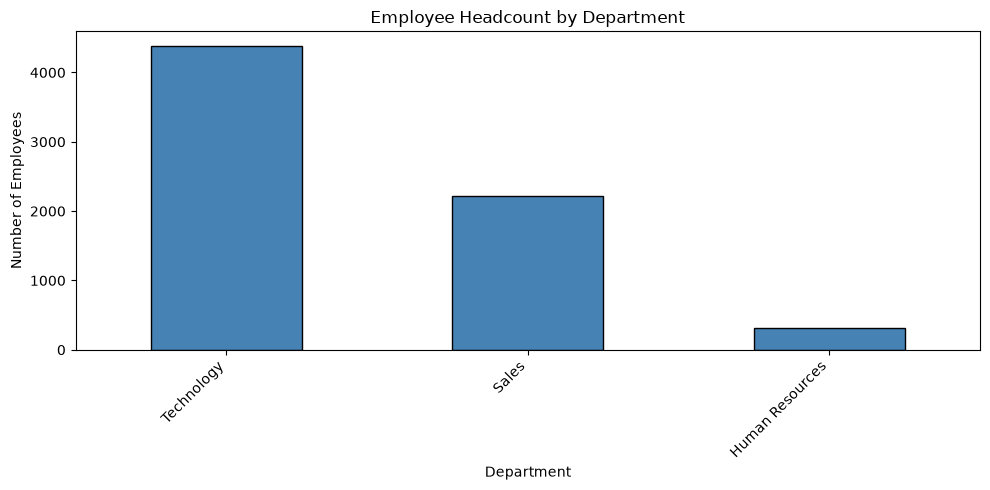

In [9]:
# Visualize Employee count by Department
plt.figure(figsize=(10, 5))
df_merged['department'].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Employee Headcount by Department')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()